In [1]:

import pandas as pd
from pathlib import Path

# Locate the processed macroeconomic dataset
data_path = Path("../data/processed/us_macro_2008_2025.csv")

if not data_path.exists():
    data_path = Path("data/processed/us_macro_2008_2025.csv")

# Load the dataset
macro = pd.read_csv(
    data_path,
    parse_dates=["observation_date"]
)

macro = macro.sort_values(
    "observation_date"
).reset_index(drop=True)

# Validate the dataset
print("Shape:", macro.shape)

print("\nDate Range:")
print(macro["observation_date"].min())
print(macro["observation_date"].max())

print("\nMissing Values:")
print(macro.isna().sum())

print("\nDuplicate Dates:",
      macro["observation_date"].duplicated().sum())

display(macro.head())


Shape: (216, 8)

Date Range:
2008-01-01 00:00:00
2025-12-01 00:00:00

Missing Values:
observation_date          0
CPIAUCSL                  1
inflation_yoy             1
FEDFUNDS                  0
fed_change_pp             0
UNRATE                    1
unemployment_change_pp    2
inflation_change_pp       3
dtype: int64

Duplicate Dates: 0


,observation_date,CPIAUCSL,inflation_yoy,FEDFUNDS,fed_change_pp,UNRATE,unemployment_change_pp,inflation_change_pp
0,2008-01-01,212.174,4.294696,3.94,-0.30,5.0,0.0,NaN
1,2008-02-01,212.687,4.142959,2.98,-0.96,4.9,-0.1,-0.151736
2,2008-03-01,213.448,3.974904,2.61,-0.37,5.1,0.2,-0.168056
3,2008-04-01,213.942,3.903761,2.28,-0.33,5.0,-0.1,-0.071143
4,2008-05-01,215.208,4.088414,1.98,-0.30,5.4,0.4,0.184653


In [2]:

# Verify that every calendar month is present
expected_months = pd.date_range(
    start=macro["observation_date"].min(),
    end=macro["observation_date"].max(),
    freq="MS"
)

missing_months = expected_months.difference(
    pd.DatetimeIndex(macro["observation_date"])
)

print("Expected months:", len(expected_months))
print("Actual observations:", len(macro))
print("Missing calendar months:", len(missing_months))

assert len(missing_months) == 0
assert len(macro) == len(expected_months)


Expected months: 216
Actual observations: 216
Missing calendar months: 0


In [3]:

# Define lag periods in months
lags = [1, 3, 6, 12]

# Create lagged interest rate changes
for lag in lags:
    macro[f"fed_change_lag_{lag}m"] = (
        macro["fed_change_pp"].shift(lag)
    )

# Inspect the new variables
lag_columns = [
    "observation_date",
    "fed_change_pp",
    "fed_change_lag_1m",
    "fed_change_lag_3m",
    "fed_change_lag_6m",
    "fed_change_lag_12m",
    "unemployment_change_pp"
]

display(macro[lag_columns].head(15))

print("\nMissing values:")
print(macro[lag_columns].isna().sum())


,observation_date,fed_change_pp,fed_change_lag_1m,fed_change_lag_3m,fed_change_lag_6m,fed_change_lag_12m,unemployment_change_pp
0,2008-01-01,-0.30,NaN,NaN,NaN,NaN,0.0
1,2008-02-01,-0.96,-0.30,NaN,NaN,NaN,-0.1
2,2008-03-01,-0.37,-0.96,NaN,NaN,NaN,0.2
3,2008-04-01,-0.33,-0.37,-0.30,NaN,NaN,-0.1
4,2008-05-01,-0.30,-0.33,-0.96,NaN,NaN,0.4
5,2008-06-01,0.02,-0.30,-0.37,NaN,NaN,0.2
6,2008-07-01,0.01,0.02,-0.33,-0.30,NaN,0.2
7,2008-08-01,-0.01,0.01,-0.30,-0.96,NaN,0.3
8,2008-09-01,-0.19,-0.01,0.02,-0.37,NaN,0.0
9,2008-10-01,-0.84,-0.19,0.01,-0.33,NaN,0.4



Missing values:
observation_date           0
fed_change_pp              0
fed_change_lag_1m          1
fed_change_lag_3m          3
fed_change_lag_6m          6
fed_change_lag_12m        12
unemployment_change_pp     2
dtype: int64


In [4]:

# Lagged correlation analysis
lags = [0, 1, 3, 6, 12]

fed_columns = ["fed_change_pp"] + [
    f"fed_change_lag_{lag}m"
    for lag in lags if lag != 0
]

# Use the same observations for every lag
analysis_data = macro[
    ["observation_date", "unemployment_change_pp"]
    + fed_columns
].dropna().copy()

results = []

for lag in lags:

    column = (
        "fed_change_pp"
        if lag == 0
        else f"fed_change_lag_{lag}m"
    )

    correlation = analysis_data[column].corr(
        analysis_data["unemployment_change_pp"]
    )

    results.append({
        "lag_months": lag,
        "pearson_r": correlation,
        "observations": len(analysis_data)
    })

lag_results = pd.DataFrame(results)

print("Fed Rate Changes vs Unemployment Changes")
display(lag_results.round(3))

print("Common sample period:")
print(analysis_data["observation_date"].min())
print(analysis_data["observation_date"].max())


Fed Rate Changes vs Unemployment Changes


,lag_months,pearson_r,observations
0,0,-0.308,202
1,1,-0.387,202
2,3,0.068,202
3,6,-0.046,202
4,12,0.002,202


Common sample period:
2009-01-01 00:00:00
2025-12-01 00:00:00


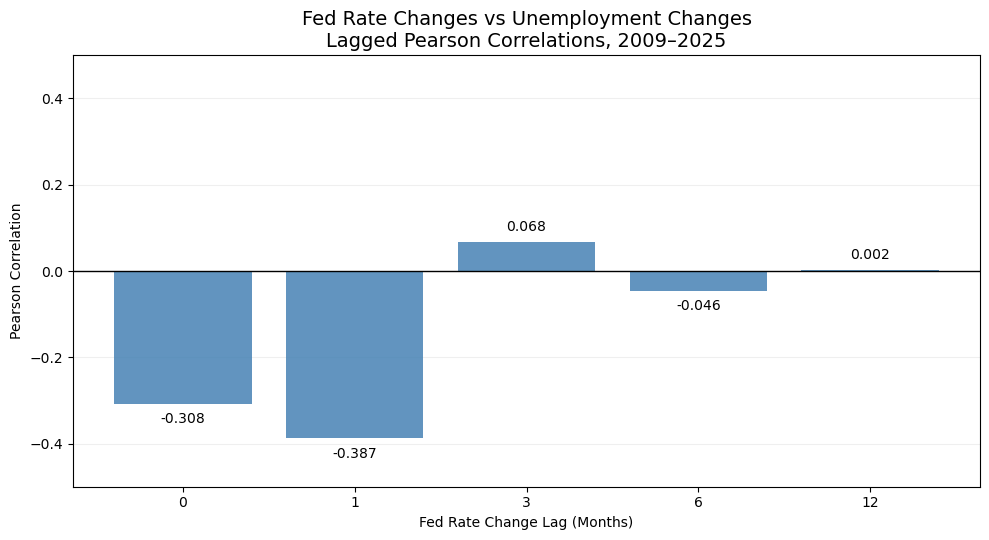

In [5]:

import matplotlib.pyplot as plt
from pathlib import Path

fig, ax = plt.subplots(figsize=(10, 5.5))

ax.bar(
    lag_results["lag_months"].astype(str),
    lag_results["pearson_r"],
    color="steelblue",
    alpha=0.85
)

ax.axhline(0, color="black", linewidth=1)

ax.set_title(
    "Fed Rate Changes vs Unemployment Changes\n"
    "Lagged Pearson Correlations, 2009–2025",
    fontsize=14
)

ax.set_xlabel("Fed Rate Change Lag (Months)")
ax.set_ylabel("Pearson Correlation")
ax.set_ylim(-0.5, 0.5)

for i, value in enumerate(lag_results["pearson_r"]):
    offset = 0.025 if value >= 0 else -0.045

    ax.text(
        i,
        value + offset,
        f"{value:.3f}",
        ha="center",
        fontsize=10
    )

ax.grid(axis="y", alpha=0.2)
ax.set_axisbelow(True)

fig.tight_layout()

output_dir = Path("../reports/figures")
output_dir.mkdir(parents=True, exist_ok=True)

fig.savefig(
    output_dir / "fed_unemployment_lag_correlations.png",
    dpi=200,
    bbox_inches="tight"
)

plt.show()


In [6]:

# Robustness Check: Excluding the COVID-19 year

# Keep the existing lag structure unchanged
without_covid = analysis_data[
    analysis_data["observation_date"].dt.year != 2020
].copy()

robustness_results = []

for lag in lags:

    column = (
        "fed_change_pp"
        if lag == 0
        else f"fed_change_lag_{lag}m"
    )

    r_full = analysis_data[column].corr(
        analysis_data["unemployment_change_pp"]
    )

    r_no_covid = without_covid[column].corr(
        without_covid["unemployment_change_pp"]
    )

    robustness_results.append({
        "lag_months": lag,
        "r_full_sample": r_full,
        "r_without_2020": r_no_covid,
        "difference": r_no_covid - r_full
    })

robustness_df = pd.DataFrame(robustness_results)

print("Full sample:", len(analysis_data))
print("Excluding 2020:", len(without_covid))

display(robustness_df.round(3))


Full sample: 202
Excluding 2020: 190


,lag_months,r_full_sample,r_without_2020,difference
0,0,-0.308,0.057,0.365
1,1,-0.387,-0.033,0.355
2,3,0.068,-0.138,-0.206
3,6,-0.046,-0.076,-0.030
4,12,0.002,-0.153,-0.155


In [7]:

# Robustness Check: Pearson vs Spearman

correlation_comparison = []

for lag in lags:

    column = (
        "fed_change_pp"
        if lag == 0
        else f"fed_change_lag_{lag}m"
    )

    correlation_comparison.append({
        "lag_months": lag,

        "pearson_full": analysis_data[column].corr(
            analysis_data["unemployment_change_pp"],
            method="pearson"
        ),

        "spearman_full": analysis_data[column].corr(
            analysis_data["unemployment_change_pp"],
            method="spearman"
        ),

        "pearson_no_2020": without_covid[column].corr(
            without_covid["unemployment_change_pp"],
            method="pearson"
        ),

        "spearman_no_2020": without_covid[column].corr(
            without_covid["unemployment_change_pp"],
            method="spearman"
        )
    })

comparison_df = pd.DataFrame(correlation_comparison)

display(comparison_df.round(3))


,lag_months,pearson_full,spearman_full,pearson_no_2020,spearman_no_2020
0,0,-0.308,0.003,0.057,0.042
1,1,-0.387,-0.009,-0.033,-0.018
2,3,0.068,0.021,-0.138,0.018
3,6,-0.046,0.032,-0.076,0.011
4,12,0.002,0.077,-0.153,0.006


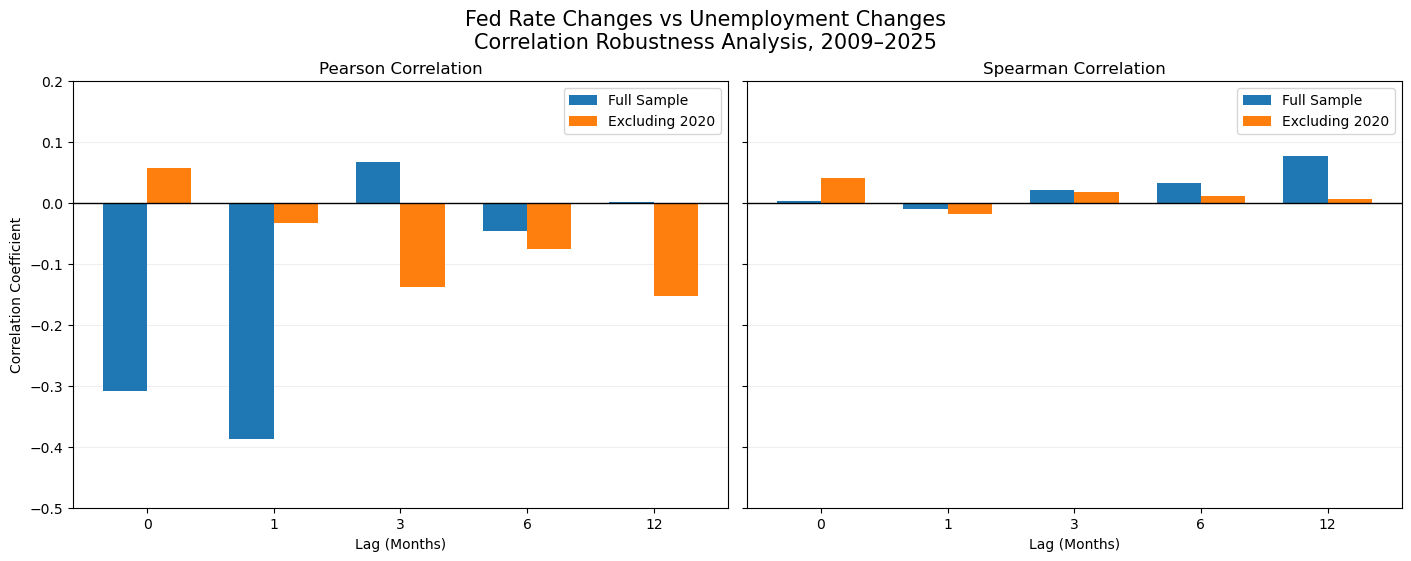

In [8]:

import numpy as np
import matplotlib.pyplot as plt
from pathlib import Path

x = np.arange(len(comparison_df))
width = 0.35

fig, axes = plt.subplots(
    1, 2,
    figsize=(14, 5.5),
    sharey=True,
    layout="constrained"
)

for ax, method, title in zip(
    axes,
    ["pearson", "spearman"],
    ["Pearson Correlation", "Spearman Correlation"]
):
    ax.bar(
        x - width / 2,
        comparison_df[f"{method}_full"],
        width,
        label="Full Sample"
    )

    ax.bar(
        x + width / 2,
        comparison_df[f"{method}_no_2020"],
        width,
        label="Excluding 2020"
    )

    ax.axhline(0, color="black", linewidth=1)
    ax.set_xticks(x)
    ax.set_xticklabels(comparison_df["lag_months"])
    ax.set_xlabel("Lag (Months)")
    ax.set_title(title)
    ax.set_ylim(-0.5, 0.2)
    ax.grid(axis="y", alpha=0.2)
    ax.set_axisbelow(True)
    ax.legend()

axes[0].set_ylabel("Correlation Coefficient")

fig.suptitle(
    "Fed Rate Changes vs Unemployment Changes\n"
    "Correlation Robustness Analysis, 2009–2025",
    fontsize=15
)

output_dir = Path("../reports/figures")
output_dir.mkdir(parents=True, exist_ok=True)

fig.savefig(
    output_dir / "macro_lag_robustness.png",
    dpi=200,
    bbox_inches="tight"
)

plt.show()



## Key Findings and Economic Interpretation

### 1. Lagged Correlations

This analysis examines the historical relationship between monthly changes in the Federal Funds Rate and changes in US unemployment from 2009 to 2025.

Five lag periods were investigated: 0, 1, 3, 6, and 12 months, using a common sample of 202 observations.

The strongest Pearson correlation was observed at a one-month lag (r = -0.387). However, this association should not be interpreted as evidence that interest rate reductions cause unemployment to increase.

Monetary policy is endogenous: the Federal Reserve may adjust interest rates in response to current or anticipated economic conditions.

### 2. Sensitivity to the COVID-19 Period

After excluding observations from 2020, the one-month Pearson correlation declined substantially in absolute magnitude, from -0.387 to -0.033.

This suggests that the original relationship was highly sensitive to the exceptional economic conditions of 2020.

The observed correlations are therefore not stable across the two sample specifications.

### 3. Pearson vs Spearman Correlations

Spearman correlations were close to zero across all examined lag periods.

For the one-month lag, the full-sample Pearson correlation was -0.387, compared with a Spearman correlation of -0.009.

This discrepancy suggests that the observed linear relationship may be disproportionately influenced by observations with unusually large changes, rather than reflecting a consistent monotonic association.

### 4. Main Economic Conclusion

The results do not provide robust evidence of a stable, simple relationship between lagged monthly interest rate changes and subsequent monthly unemployment changes.

This does not imply that monetary policy has no effect on employment. Rather, the relationship is likely more complex than can be captured through simple bivariate correlations.

## Methodological Limitations

- Correlation does not establish causality.
- Monetary policy decisions may respond to expected economic developments, creating endogeneity.
- Extreme economic events can disproportionately influence Pearson correlations.
- Monthly changes may fail to capture cumulative monetary policy effects over longer horizons.
- Lagged correlations do not control for other macroeconomic variables or time-series dependence.
- Excluding 2020 does not eliminate all pandemic-related effects from the sample.
- The analysis is exploratory and does not constitute a formal econometric identification strategy.

## Implications for the Project

These findings demonstrate the importance of robustness checks when investigating macroeconomic relationships.

The next phase will incorporate financial market data to examine whether macroeconomic conditions are associated with differences in asset returns, volatility, and portfolio performance.
